# Structured Product Project

In [1]:
import pandas as pd
import numpy as np
import math
import datetime as dt
import strategy as strat
import matplotlib.pyplot as plt

## Data Retrieving

### Eonia Index and EURIBOR for the risk-free rate (data retrieved from Bloomberg on June 11)

discount factor: if I invest money at the risk-free rate, I get back in the future the price you give me
    take realized FTSE over the last few months
    diffuse Heston rate and retrieve the FX
    we will also need to diffuse FX

In [2]:
marketRates = pd.Series()
marketRates[0.002688] = -0.00476
marketRates[0.083333] = -0.00549
marketRates[0.25]=-0.00545
marketRates[0.5]=-0.00519
marketRates[1.0]=-0.005126
marketRates[2.0]=-0.004821
marketRates[3.0]=-0.00432
marketRates[4.0]=-0.003672
marketRates[5.0]=-0.002960
marketRates[6.0]=-0.002208
marketRates[7.0]=-0.001447
marketRates[8.0]=-0.000697
marketRates[9.0]=0.000040
marketRates[10.0]=0.000718
marketRates[15.0]=0.00338
marketRates[20.0]=0.004563
marketRates[30.0]=0.004683

In [3]:
marketRates

,0
0.002688,-0.004760
0.083333,-0.005490
0.250000,-0.005450
0.500000,-0.005190
1.000000,-0.005126
2.000000,-0.004821
3.000000,-0.004320
4.000000,-0.003672
5.000000,-0.002960
6.000000,-0.002208


In [5]:
#Historical Price and 260d volatility of the underlying taken from bloomberg
data_historic = pd.read_excel("/content/historic_data_sx5e.xlsx")
data_historic.set_index(["Dates"],inplace=True)

In [6]:
data_historic

,PX_LAST,VOLATILITY_260D
Dates,,
2018-01-18,3620.91,10.44
2018-01-19,3649.07,10.42
2018-01-22,3665.28,10.43
2018-01-23,3672.29,10.42
2018-01-24,3643.22,10.46
...,...,...
2021-06-02,4088.50,19.50
2021-06-03,4079.24,19.49
2021-06-04,4089.38,19.33


### SP Parameters

In [7]:
date_exercice = dt.datetime(2018,1,18)
strike = data_historic.loc[date_exercice]["PX_LAST"]
flt_barrier_bonus = 0.7
redemption_level = 100
flt_bonus = 5.5
capital_barrier = 0.6

In [8]:
S_init = [data_historic.iloc[-1,0]] ##on va commencer la diffusion en utilisant le prix du 8/06/2021
vol = pd.Series([data_historic.iloc[-1,-1]])/100
div = pd.Series([0.0267])### Projected 12M Div Yield, retrieve from Bloomberg
cal_date = data_historic.index[-1]#.date() ## au 8/06/2021
first_observation = dt.datetime(2019,1,11)
last_observation = dt.datetime(2028,1,11)
s_date_index = pd.date_range(first_observation.replace(day=1), last_observation, freq = "12MS") + pd.offsets.Day(first_observation.day-2) + pd.offsets.BDay(1)
int_nbre_date = len(s_date_index) - list(cal_date>s_date_index).index(False) + 1

In [9]:
int_nbre_date

8

In [10]:
s_date_index

DatetimeIndex(['2019-01-11', '2020-01-13', '2021-01-11', '2022-01-11',
               '2023-01-11', '2024-01-11', '2025-01-13', '2026-01-12',
               '2027-01-11', '2028-01-11'],
              dtype='datetime64[ns]', freq=None)

In [11]:
cal_date>s_date_index

array([ True,  True,  True, False, False, False, False, False, False,
       False])

In [12]:
## payment date : on crée la série des dates de payments utilisée pour déterminer le Discount Factor
payment_init = dt.datetime(2019,1,18)
maturity = dt.datetime(2028,1,18)
s_payment_index = pd.date_range(payment_init.replace(day=1), maturity, freq = "12MS") + pd.offsets.Day(payment_init.day-2) + pd.offsets.BDay(1)

s_calcul_date = s_date_index[list(cal_date<s_date_index)]
s_calcul_date = [d.date() for d in s_calcul_date]
s_payment_date = s_date_index[list(cal_date<s_payment_index)]
s_payment_date = [d.date() for d in s_payment_date]

## Calcul du Timestep
timestep = pd.Series()
delta = pd.Series()
timestep[cal_date.date()] = 0
delta[cal_date.date()] = 0

d_ex = cal_date.date()
for d in s_calcul_date:
    timestep[d] = (d-cal_date.date()).days/365
    delta[d] = (d-d_ex).days/365
    d_ex = d

paymentstep = pd.Series()
paymentstep[cal_date.date()] = 0
d_ex = cal_date.date()
for d in s_payment_date:
    paymentstep[d] = (d-cal_date.date()).days/365
    d_ex = d

forwarddiscount = []
forwarddiscount.append(0)
for i in range(1,int_nbre_date):
    index_sup = list(paymentstep[i] > marketRates.index).index(False)
    ## interpolation selon la formule de Taylor-Young : f(x) = f(a) + (f(b)-f(a)) * (x-a)/(b-a)
    forwarddiscount.append(marketRates.iloc[index_sup-1] + (marketRates.iloc[index_sup]-marketRates.iloc[index_sup-1])*(paymentstep[i]-marketRates.index[index_sup-1])/(marketRates.index[index_sup]-marketRates.index[index_sup-1]))


DF = []
spread = 0
DF.append(0)
DF.append(1/((1+forwarddiscount[1]+spread)**paymentstep[1]))
for i in range(2,len(forwarddiscount)):
    d_t = paymentstep[i] - paymentstep[i-1]
    DF.append(DF[i-1]/((1+forwarddiscount[i])**d_t))

riskfree = []
riskfree.append(0)
for i in range(1,int_nbre_date):
    index_sup = list(timestep[i] > marketRates.index).index(False)
    ## interpolation selon la formule de Taylor-Young : f(x) = f(a) + (f(b)-f(a)) * (x-a)/(b-a)
    riskfree.append(marketRates.iloc[index_sup-1] + (marketRates.iloc[index_sup]-marketRates.iloc[index_sup-1])*(timestep[i]-marketRates.index[index_sup-1])/(marketRates.index[index_sup]-marketRates.index[index_sup-1]))

/tmp/ipykernel_449/1470222155.py:33: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  index_sup = list(paymentstep[i] > marketRates.index).index(False)
/tmp/ipykernel_449/1470222155.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  forwarddiscount.append(marketRates.iloc[index_sup-1] + (marketRates.iloc[index_sup]-marketRates.iloc[index_sup-1])*(paymentstep[i]-marketRates.index[index_sup-1])/(marketRates.index[index_sup]-marketRates.index[index_sup-1]))
/tmp/ipykernel_449/1470222155.py:41: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be trea

In [13]:
DF

[0,
 np.float64(1.0030911338544917),
 np.float64(1.008075736951557),
 np.float64(1.0126561276601824),
 np.float64(1.0166838807171594),
 np.float64(1.019984473501312),
 np.float64(1.0225449155649768),
 np.float64(1.0243410822173684)]

## Historical Observation

In [14]:
s_historic = s_date_index[list(cal_date>s_date_index)]
s_historic = [d.date() for d in s_historic]
historic = data_historic.loc[s_historic]["PX_LAST"]

In [15]:
s_historic

[datetime.date(2019, 1, 11),
 datetime.date(2020, 1, 13),
 datetime.date(2021, 1, 11)]

In [16]:
coupon_du = 0
for t in range(len(historic)):
    if historic.iloc[t] >= strike*flt_barrier_bonus:
        coupon_du +=1
coupon_du

3

## BS Diffusion

In [17]:
int_nbre_path = 10000
np.random.seed(42)  # fixed seed so results are reproducible
gauss = np.random.normal(0,1,size=(int_nbre_path,int_nbre_date - 1,1))
matrice_alea = gauss * vol.values

In [18]:
np.random.seed(43)  # fixed seed so results are reproducible
diffusion_matrix = strat.Generate_Trajectory_BS(S_init, riskfree, div, vol, delta, np.random.normal(0,1,size=(int_nbre_path,int_nbre_date - 1,1)) * vol.values, int_nbre_path)

/content/strategy.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  diffusion_matrix[j] = diffusion_matrix[j-1] * ((riskfree[j] - div - 0.5*vol**2)*delta[j] + math.sqrt(delta[j])*pd.DataFrame(matrice_alea[:,j-1,:])).applymap(math.exp)
/content/strategy.py:31: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_matrix[j] = diffusion_matrix[j-1] * ((riskfree[j] - div - 0.5*vol**2)*delta[j] + math.sqrt(delta[j])*pd.DataFrame(matrice_alea[:,j-1,:])).applymap(math.exp)


## Payoff

In [19]:
#diffusion_matrix = strat.Generate_Trajectory_BS(S_init, riskfree, div, vol, delta, np.random.normal(0,1,size=(int_nbre_path,int_nbre_date - 1,1)) * vol.values, nbre_path = 10000)
histo = pd.DataFrame(np.zeros(diffusion_matrix[0].shape)) #permet de récupérer les cash flows
price = pd.DataFrame(np.zeros(diffusion_matrix[0].shape))

#coupon dû (payé à maturité)
coupon_infine = pd.DataFrame(np.zeros(diffusion_matrix[0].shape)) + coupon_du


for t in range(1,len(diffusion_matrix)):
    #barrière de bonus
    isbonus = diffusion_matrix[t] >= strike*flt_barrier_bonus
    coupon_infine = coupon_infine + (isbonus)

    if t == (len(diffusion_matrix)-1):
    #maturity case
        #payement des coupons dû à maturité
        price = price + DF[t] * coupon_infine * flt_bonus
        histo = histo + coupon_infine * flt_bonus

        #au dessus de la barrière de capital qd produit non expiré : remboursement de 100% du nominal
        isabovecapital = diffusion_matrix[t] >= strike*capital_barrier
        price = price + DF[t] * redemption_level * (isabovecapital)
        histo = histo + redemption_level * (isabovecapital)

        #en dessous du capital : remboursement (diffusion_matrix[t] / strike) %
        price = price + DF[t] * 100 * diffusion_matrix[t] / strike  * (~isabovecapital)
        histo = histo+ 100 * diffusion_matrix[t] / strike * (~isabovecapital)

price.mean()

,0
0,136.926603


#### With the BS model, we price the Anthemis at 136.92%

## Greeks

#### Delta of the SP

In [20]:
S_up = [S_init[0] * 1.05]
S_down = [S_init[0] * 0.95]

In [21]:
diffusion_matrix_up = strat.Generate_Trajectory_BS(S_up, riskfree, div, vol, delta, matrice_alea, nbre_path = 10000)
prix_up = strat.Pricing_Anthemis(diffusion_matrix_up,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)

In [22]:
diffusion_matrix_down = strat.Generate_Trajectory_BS(S_down, riskfree, div, vol, delta, matrice_alea, nbre_path = 10000)
prix_down = strat.Pricing_Anthemis(diffusion_matrix_down,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)

In [23]:
delta_ps = (prix_up - prix_down) / (2 * 0.05)
delta_ps

np.float64(64.67362228446262)

#### Delta

In [24]:
bump = 5
spot = np.arange(0.2,2,0.01) * strike

In [25]:
price_delta = []
for i in range(len(spot)):
    diffusion_matrix = strat.Generate_Trajectory_BS(spot[i], riskfree, div, vol, delta, matrice_alea, nbre_path = 10000)
    price_delta.append(strat.Pricing_Anthemis(diffusion_matrix,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level))

In [26]:
Delta = (pd.Series(price_delta[bump:])-pd.Series(price_delta[0:-bump]))/(2*bump)

Text(0.5, 1.0, 'Delta')

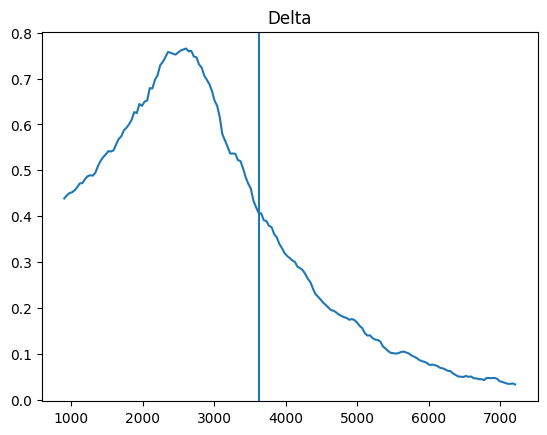

In [27]:
plt.plot(spot[bump:],Delta)
plt.axvline(x=strike)
plt.title("Delta")

#### Gamma

Text(0.5, 1.0, 'Gamma')

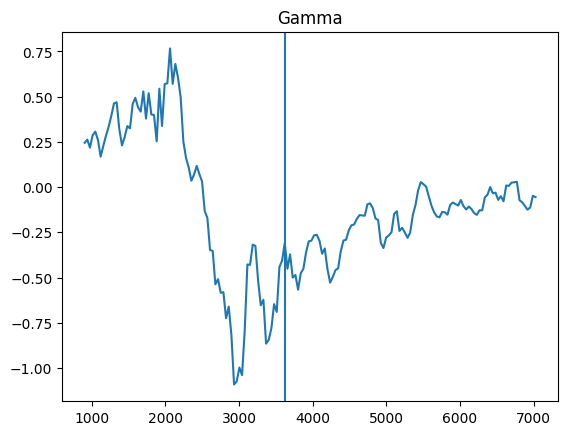

In [28]:
gamma = (pd.Series(price_delta[2*bump:]) + pd.Series(price_delta[0:-2*bump]) - 2 * pd.Series(price_delta[bump:-bump]))
plt.plot(spot[bump:-bump],gamma)
plt.axvline(x=strike)
plt.title("Gamma")

#### Vega

In [29]:
bump = 0.01
price_vega_up = []
price_vega_down = []
for i in range(len(spot)):
    diffusion_matrix_up = strat.Generate_Trajectory_BS(spot[i], riskfree, div, vol + bump, delta, matrice_alea, nbre_path = 10000)
    price_vega_up.append(strat.Pricing_Anthemis(diffusion_matrix_up,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level))
    diffusion_matrix_down = strat.Generate_Trajectory_BS(spot[i], riskfree, div, vol - bump, delta, matrice_alea, nbre_path = 10000)
    price_vega_down.append(strat.Pricing_Anthemis(diffusion_matrix_down,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level))

Text(0.5, 1.0, 'Vega')

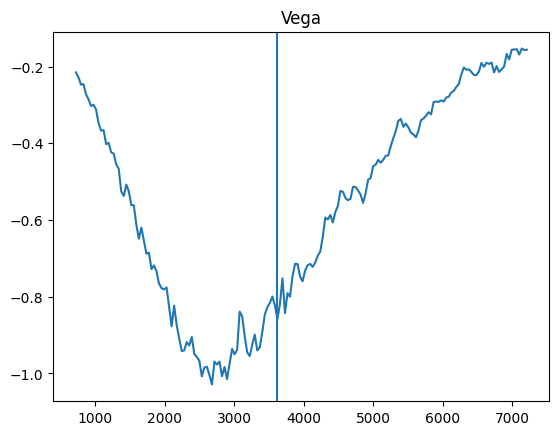

In [30]:
vega = (pd.Series(price_vega_up) - pd.Series(price_vega_down))/(2*bump*100)
plt.plot(spot,vega)
plt.axvline(x=strike)
plt.title("Vega")

## Diffusion Heston

In [31]:
V0 = vol[0]**2;
Eta = 1.5 #vol de vol (ie) variance
Theta = vol[0]**2 #Dans le modèle, on simule la variance => Theta = variance à l'infini, variance long terme
Kappa = 2 #force de retour à la moyenne (ie) mean reversion
Rho = -0.85 #corrélation entre les 2 lois normales (ie) le spot et la vol

In [32]:
vol

,0
0,0.1903


In [33]:
vol[0]**2

np.float64(0.03621409000000001)

#### Riskfree for Heston diffusion

In [34]:
dT=0.01 #pr une année qui contient 252 jours, cela correspon à ~2jours
Dates=np.arange(0,timestep.iloc[-1],dT)
Dates=sorted(list(set().union(Dates,timestep.values)));
riskfree_heston = []
riskfree_heston.append(0)
for i in range(1,len(Dates)):
    index_sup = list(Dates[i] > marketRates.index).index(False)
    ## interpolation selon la formule de Taylor-Young : f(x) = f(a) + (f(b)-f(a)) * (x-a)/(b-a)
    riskfree_heston.append(marketRates.iloc[index_sup-1] + (marketRates.iloc[index_sup]-marketRates.iloc[index_sup-1])*(Dates[i]-marketRates.index[index_sup-1])/(marketRates.index[index_sup]-marketRates.index[index_sup-1]))

In [35]:
np.random.seed(44)  # fixed seed so results are reproducible
Normal_Maxtrix_Temp = np.random.normal(0,1,size=(int_nbre_path,len(Dates) - 1,1))
Normal_Maxtrix_Spot = np.random.normal(0,1,size=(int_nbre_path,len(Dates) - 1,1))

In [36]:
dict_heston = strat.Generate_Trajectory_Heston(S_init,riskfree_heston,div,timestep,V0,Eta,Theta,Kappa,Rho,int_nbre_path,Normal_Maxtrix_Spot,Normal_Maxtrix_Temp)

/content/strategy.py:93: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_matrix[j] = diffusion_matrix[j-1] * ((riskfree[j] - div - 0.5*diffusion_var[j-1])*Delta_t.iloc[j-1] + (Delta_t.iloc[j-1] * diffusion_var[j-1]).applymap(math.sqrt) * Normal_Maxtrix_Spot[:,j-1,:]).applymap(math.exp)
/content/strategy.py:96: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_var[j] = diffusion_var[j-1] + Kappa * (Theta-diffusion_var[j-1])*Delta_t.iloc[j-1]+Eta*(diffusion_var[j-1]).applymap(math.sqrt)*Normal_Maxtrix_Vol[:,j-1,:]*math.sqrt(Delta_t.iloc[j-1])
/content/strategy.py:98: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_var[j] = diffusion_var[j] * ispositive + (~ispositive) * (diffusion_var[j-1] + Kappa * (Theta-diffusion_var[j-1])*Delta_t.iloc[j-1] + Eta*(diffusion_var[j-1]).applymap(math.sqrt)*(-Normal_Maxtrix_Vol[:,j-1,:])*math.sqrt(Delta_t.iloc[j-1]))
/con

In [37]:
diffusion_heston = dict_heston["diffusion"]

In [38]:
strat.Pricing_Anthemis(diffusion_heston,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)

np.float64(103.16811489292773)

In [39]:
dict_heston["diffusion"]

{0:             0
 0     4096.01
 1     4096.01
 2     4096.01
 3     4096.01
 4     4096.01
 ...       ...
 9995  4096.01
 9996  4096.01
 9997  4096.01
 9998  4096.01
 9999  4096.01
 
 [10000 rows x 1 columns],
 1:                 0
 0     6109.051459
 1     3460.654664
 2     3431.835839
 3     4562.241940
 4     5769.428844
 ...           ...
 9995  3450.217075
 9996  4585.892328
 9997  4618.781202
 9998  3176.614407
 9999  3865.657787
 
 [10000 rows x 1 columns],
 2:                 0
 0     6318.695202
 1     3045.012811
 2     3922.690420
 3     5066.699721
 4     5178.187849
 ...           ...
 9995  3965.267643
 9996  1406.624741
 9997  3479.858583
 9998  3259.521574
 9999  4207.246422
 
 [10000 rows x 1 columns],
 3:                 0
 0     7554.326408
 1     4162.073166
 2     6274.604374
 3     5675.304165
 4     8841.610574
 ...           ...
 9995  4124.984139
 9996  3587.174040
 9997  1082.085011
 9998  2909.272777
 9999  9151.377669
 
 [10000 rows x 1 columns],
 4:     

#### With the Heston model, we price the Anthemis at 102.83%

### Greeks

### Sensitivity to RHO

In [40]:
eps = 0.05
Rho_up = Rho+eps
Rho_down = Rho-eps

dict_heston_up = strat.Generate_Trajectory_Heston(S_init,riskfree_heston,div,timestep,V0,Eta,Theta,Kappa,Rho_up,int_nbre_path,Normal_Maxtrix_Spot,Normal_Maxtrix_Temp)
dict_heston_down = strat.Generate_Trajectory_Heston(S_init,riskfree_heston,div,timestep,V0,Eta,Theta,Kappa,Rho_down,int_nbre_path,Normal_Maxtrix_Spot,Normal_Maxtrix_Temp)

diffusion_heston_up = dict_heston_up["diffusion"]
diffusion_heston_down = dict_heston_down["diffusion"]

/content/strategy.py:93: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_matrix[j] = diffusion_matrix[j-1] * ((riskfree[j] - div - 0.5*diffusion_var[j-1])*Delta_t.iloc[j-1] + (Delta_t.iloc[j-1] * diffusion_var[j-1]).applymap(math.sqrt) * Normal_Maxtrix_Spot[:,j-1,:]).applymap(math.exp)
/content/strategy.py:96: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_var[j] = diffusion_var[j-1] + Kappa * (Theta-diffusion_var[j-1])*Delta_t.iloc[j-1]+Eta*(diffusion_var[j-1]).applymap(math.sqrt)*Normal_Maxtrix_Vol[:,j-1,:]*math.sqrt(Delta_t.iloc[j-1])
/content/strategy.py:98: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  diffusion_var[j] = diffusion_var[j] * ispositive + (~ispositive) * (diffusion_var[j-1] + Kappa * (Theta-diffusion_var[j-1])*Delta_t.iloc[j-1] + Eta*(diffusion_var[j-1]).applymap(math.sqrt)*(-Normal_Maxtrix_Vol[:,j-1,:])*math.sqrt(Delta_t.iloc[j-1]))
/con

In [41]:
P_up = strat.Pricing_Anthemis(diffusion_heston_up,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)
P_down = strat.Pricing_Anthemis(diffusion_heston_down,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)

grec_rho = (P_up - P_down)/(2*eps)
grec_rho

np.float64(-10.21499394177269)

### Sensitivity to Eta

In [42]:
eps = 0.1
Eta_up = Eta+eps
Eta_down = Eta-eps

dict_heston_eta_up = strat.Generate_Trajectory_Heston(S_init,riskfree_heston,div,timestep,V0,Eta_up,Theta,Kappa,Rho,int_nbre_path,Normal_Maxtrix_Spot,Normal_Maxtrix_Temp)
dict_heston_eta_down = strat.Generate_Trajectory_Heston(S_init,riskfree_heston,div,timestep,V0,Eta_down,Theta,Kappa,Rho,int_nbre_path,Normal_Maxtrix_Spot,Normal_Maxtrix_Temp)

diffusion_heston_eta_up = dict_heston_eta_up["diffusion"]
diffusion_heston_eta_down = dict_heston_eta_down["diffusion"]

In [43]:
P_eta_up = strat.Pricing_Anthemis(diffusion_heston_eta_up,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)
P_eta_down = strat.Pricing_Anthemis(diffusion_heston_eta_down,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)

grec_eta = (P_eta_up - P_eta_down)/(2*eps)
grec_eta

np.float64(-29.028142300441075)

In [44]:
Eta_null = 0
dict_heston_eta_null = strat.Generate_Trajectory_Heston(S_init,riskfree_heston,div,timestep,V0,Eta_null,Theta,Kappa,Rho,int_nbre_path,Normal_Maxtrix_Spot,Normal_Maxtrix_Temp)

diffusion_heston_eta_null = dict_heston_eta_null["diffusion"]
P_eta_null = strat.Pricing_Anthemis(diffusion_heston_eta_null,coupon_du,strike,flt_barrier_bonus,DF,flt_bonus,capital_barrier,redemption_level)

In [45]:
P_eta_null

np.float64(136.7172086176602)